In [1]:
from sklearn.neighbors import KernelDensity
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV
import seaborn as sns

In [8]:
diamonds = sns.load_dataset('diamonds')
X = diamonds[['carat', 'price']]

scaler = StandardScaler()
X_standard = scaler.fit_transform(X)

np.random.seed(42) 
indices_muestra = np.random.choice(X_standard.shape[0], size=5000, replace=False)
X_muestra = X_standard[indices_muestra]

bandws = np.linspace(0.05, 1, 50)
grid_search = GridSearchCV(KernelDensity(kernel='gaussian'), {'bandwidth':bandws}, cv=5)
grid_search.fit(X_muestra)
print('best bandwidth ', grid_search.best_params_ )

best_bw = grid_search.best_params_['bandwidth']

kde = KernelDensity(kernel='gaussian', bandwidth=best_bw)
kde.fit(X_standard)

#log_density = kde.score_samples(X_standard)
# print(log_density)
#density = np.exp(log_density)



best bandwidth  {'bandwidth': np.float64(0.05)}


,"bandwidth bandwidth: float or {""scott"", ""silverman""}, default=1.0The bandwidth of the kernel. If bandwidth is a float, it defines thebandwidth of the kernel. If bandwidth is a string, one of the estimationmethods is implemented.",np.float64(0.05)
,"algorithm algorithm: {'kd_tree', 'ball_tree', 'auto'}, default='auto'The tree algorithm to use.",'auto'
,"kernel kernel: {'gaussian', 'tophat', 'epanechnikov', 'exponential', 'linear', 'cosine'}, default='gaussian'The kernel to use.",'gaussian'
,"metric metric: str, default='euclidean'Metric to use for distance computation. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.Not all metrics are valid with all algorithms: refer to thedocumentation of :class:`BallTree` and :class:`KDTree`. Note that thenormalization of the density output is correct only for the Euclideandistance metric.",'euclidean'
,"atol atol: float, default=0The desired absolute tolerance of the result. A larger tolerance willgenerally lead to faster execution.",0
,"rtol rtol: float, default=0The desired relative tolerance of the result. A larger tolerance willgenerally lead to faster execution.",0
,"breadth_first breadth_first: bool, default=TrueIf true (default), use a breadth-first approach to the problem.Otherwise use a depth-first approach.",True
,"leaf_size leaf_size: int, default=40Specify the leaf size of the underlying tree. See :class:`BallTree`or :class:`KDTree` for details.",40
,"metric_params metric_params: dict, default=NoneAdditional parameters to be passed to the tree for use with themetric. For more information, see the documentation of:class:`BallTree` or :class:`KDTree`.",None
Name,Type,Value
"bandwidth_ bandwidth_: floatValue of the bandwidth, given directly by the bandwidth parameter orestimated using the 'scott' or 'silverman' method... versionadded:: 1.0",float64,0.05


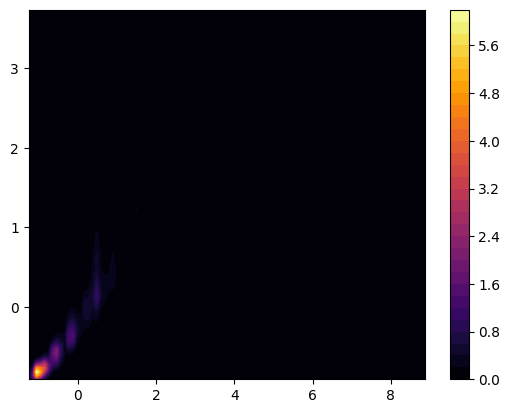

In [10]:
x = np.linspace(X_standard[:,0].min(), X_standard[:,0].max(), 100)
y = np.linspace(X_standard[:,1].min(), X_standard[:,1].max(), 100)
xx, yy = np.meshgrid(x,y)
grid = np.column_stack([xx.ravel(), yy.ravel()])
log_density = kde.score_samples(grid)
density = np.exp(log_density)

###
density = density.reshape(xx.shape)

plt.contourf(xx, yy, density, levels = 30, cmap='inferno')
plt.colorbar()
plt.show()

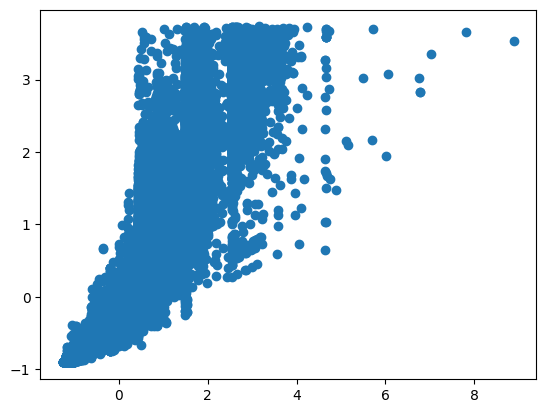

In [12]:
plt.scatter(X_standard[:,0], X_standard[:,1])